# Lab 2. Трансформер на NumPy: демо и обучение

Ноутбук показывает, что NumPy-реализация повторяет `torch.nn.TransformerEncoderLayer` и
`torch.nn.TransformerEncoder`, а затем обучает маленький классификатор на задаче
XOR первых и последних токенов последовательности.

Запуск из директории `part_2_transformer`:

```bash
../.venv/bin/jupyter notebook main.ipynb
```


In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src" / "nptorch").exists():
    ROOT = ROOT / "part_2_transformer"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.nptorch import Parameter, Tensor, manual_seed, nn, no_grad, optim
from src.nptorch import functional as F

print(f"python {sys.version.split()[0]} | torch {torch.__version__} | numpy {np.__version__}")
print(f"nptorch: {ROOT / 'src' / 'nptorch'}")


def copy_weights(torch_module, np_module):
    np_module.load_state_dict(
        {key: value.detach().cpu().numpy() for key, value in torch_module.state_dict().items()}
    )


def maxdiff(a, b):
    return float(np.max(np.abs(np.asarray(a) - np.asarray(b))))


python 3.12.3 | torch 2.15.0+cpu | numpy 2.5.5
nptorch: /home/kitsu/ml_lab_2/part_2_transformer/src/nptorch


## 1. Сравнение `TransformerEncoderLayer` с torch

Одинаковые веса загружаются из torch в NumPy-слой. Сравниваются выход, loss, градиент
входа и градиенты всех параметров. Используются bool-маска и padding-маска.

In [2]:
D_MODEL, NHEAD, FFN = 32, 4, 64
torch.manual_seed(0)
torch_layer = torch.nn.TransformerEncoderLayer(
    D_MODEL, NHEAD, dim_feedforward=FFN, dtype=torch.float64
).eval()
np_layer = nn.TransformerEncoderLayer(
    D_MODEL, NHEAD, dim_feedforward=FFN, dtype=np.float64
).eval()
copy_weights(torch_layer, np_layer)

rng = np.random.default_rng(1)
x = rng.standard_normal((6, 3, D_MODEL))
src_mask = np.triu(np.ones((6, 6), dtype=bool), k=1)
key_padding_mask = np.zeros((3, 6), dtype=bool)
key_padding_mask[0, -2:] = True

xt = torch.tensor(x, requires_grad=True)
xn = Tensor(x.copy(), requires_grad=True)
out_t = torch_layer(
    xt,
    src_mask=torch.tensor(src_mask),
    src_key_padding_mask=torch.tensor(key_padding_mask),
)
out_n = np_layer(
    xn,
    src_mask=src_mask,
    src_key_padding_mask=key_padding_mask,
)
coeff = rng.standard_normal(out_t.shape)
loss_t = (out_t * torch.tensor(coeff)).sum()
loss_n = (out_n * Tensor(coeff)).sum()
loss_t.backward()
loss_n.backward()

param_diff = max(
    maxdiff(param.grad.data, dict(torch_layer.named_parameters())[name].grad.numpy())
    for name, param in np_layer.named_parameters()
)
print(f"layer forward maxdiff : {maxdiff(out_n.data, out_t.detach().numpy()):.3e}")
print(f"layer loss diff      : {abs(loss_n.item() - loss_t.item()):.3e}")
print(f"layer input grad diff: {maxdiff(xn.grad.data, xt.grad.numpy()):.3e}")
print(f"layer param grad diff: {param_diff:.3e}")
print(f"parameter tensors    : {len(list(np_layer.named_parameters()))}")


layer forward maxdiff : 8.882e-16
layer loss diff      : 7.105e-15
layer input grad diff: 2.220e-15
layer param grad diff: 3.553e-15
parameter tensors    : 12


## 2. Сравнение `TransformerEncoder` с torch

Стек из двух слоёв, финальный `LayerNorm`, bool-маска и `key_padding_mask`.
Сравниваются forward, loss, градиент входа и все градиенты параметров.

In [3]:
torch_layer2 = torch.nn.TransformerEncoderLayer(
    D_MODEL, NHEAD, dim_feedforward=FFN, dtype=torch.float64
)
np_layer2 = nn.TransformerEncoderLayer(
    D_MODEL, NHEAD, dim_feedforward=FFN, dtype=np.float64
)
torch_encoder = torch.nn.TransformerEncoder(
    torch_layer2,
    2,
    norm=torch.nn.LayerNorm(D_MODEL, dtype=torch.float64),
    enable_nested_tensor=False,
).eval()
np_encoder = nn.TransformerEncoder(
    np_layer2,
    2,
    norm=nn.LayerNorm(D_MODEL, dtype=np.float64),
    enable_nested_tensor=False,
).eval()
copy_weights(torch_encoder, np_encoder)

x = rng.standard_normal((5, 3, D_MODEL))
src_mask = np.triu(np.ones((5, 5), dtype=bool), k=1)
key_padding_mask = np.zeros((3, 5), dtype=bool)
key_padding_mask[1, -1] = True

xt = torch.tensor(x, requires_grad=True)
xn = Tensor(x.copy(), requires_grad=True)
out_t = torch_encoder(
    xt,
    mask=torch.tensor(src_mask),
    src_key_padding_mask=torch.tensor(key_padding_mask),
)
out_n = np_encoder(
    xn,
    mask=src_mask,
    src_key_padding_mask=key_padding_mask,
)
coeff = rng.standard_normal(out_t.shape)
loss_t = (out_t * torch.tensor(coeff)).sum()
loss_n = (out_n * Tensor(coeff)).sum()
loss_t.backward()
loss_n.backward()

param_diff = max(
    maxdiff(param.grad.data, dict(torch_encoder.named_parameters())[name].grad.numpy())
    for name, param in np_encoder.named_parameters()
)
print(f"encoder forward maxdiff : {maxdiff(out_n.data, out_t.detach().numpy()):.3e}")
print(f"encoder loss diff       : {abs(loss_n.item() - loss_t.item()):.3e}")
print(f"encoder input grad diff : {maxdiff(xn.grad.data, xt.grad.numpy()):.3e}")
print(f"encoder param grad diff : {param_diff:.3e}")
print(f"parameter tensors       : {len(list(np_encoder.named_parameters()))}")
print(f"state_dict keys match   : {list(torch_encoder.state_dict()) == list(np_encoder.state_dict())}")


encoder forward maxdiff : 8.882e-16
encoder loss diff       : 1.332e-14
encoder input grad diff : 1.110e-15
encoder param grad diff : 5.329e-15
parameter tensors       : 26
state_dict keys match   : True


## 3. Простое обучение: XOR первых и последних токенов

Задача: на вход подаётся последовательность из 8 бинарных токенов, нужно предсказать
XOR первого и последнего токенов. Модель:

- линейная проекция one-hot токена в `d_model=32`;
- обучаемое позиционное смещение;
- `TransformerEncoder` из двух слоёв с финальным `LayerNorm`;
- mean-pooling по последовательности и линейный классификатор на 2 класса.

Loss — negative log-likelihood по one-hot меткам, оптимизатор — `AdamW`.
Dropout выключен (`p=0`), чтобы сравнение с torch-двойником было численно точным.

In [4]:
SEQ_LEN = 8
VOCAB = 2
N_TRAIN = 800
N_VAL = 224
D_MODEL = 32
NHEAD = 4
FFN = 64
N_LAYERS = 2
BATCH_SIZE = 64
STEPS = 300
LR = 3e-3


def make_data(seed=0):
    rng_data = np.random.default_rng(seed)
    tokens = rng_data.integers(0, VOCAB, size=(N_TRAIN + N_VAL, SEQ_LEN))
    labels = (tokens[:, 0] ^ tokens[:, -1]).astype(np.int64)
    onehot = np.eye(VOCAB, dtype=np.float64)[tokens].transpose(1, 0, 2)
    x_train, x_val = onehot[:, :N_TRAIN, :], onehot[:, N_TRAIN:, :]
    y_train = np.eye(VOCAB, dtype=np.float64)[labels[:N_TRAIN]]
    y_val = np.eye(VOCAB, dtype=np.float64)[labels[N_TRAIN:]]
    return x_train, y_train, labels[:N_TRAIN], x_val, y_val, labels[N_TRAIN:]


x_train, y_train, labels_train, x_val, y_val, labels_val = make_data(seed=0)
print(f"train: {x_train.shape} tokens  val: {x_val.shape} tokens")
print(f"class balance (train): {np.bincount(labels_train) / len(labels_train)}")


class TinyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Linear(VOCAB, D_MODEL, dtype=np.float64)
        self.pos = Parameter(np.zeros((SEQ_LEN, 1, D_MODEL), dtype=np.float64))
        encoder_layer = nn.TransformerEncoderLayer(
            D_MODEL,
            NHEAD,
            dim_feedforward=FFN,
            dropout=0.0,
            dtype=np.float64,
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            N_LAYERS,
            norm=nn.LayerNorm(D_MODEL, dtype=np.float64),
            enable_nested_tensor=False,
        )
        self.head = nn.Linear(D_MODEL, VOCAB, dtype=np.float64)

    def forward(self, onehot):
        hidden = self.embed(onehot) + self.pos
        hidden = self.encoder(hidden)
        pooled = hidden.mean(dim=0)
        return self.head(pooled)


def accuracy(model, onehot, labels):
    model.eval()
    with no_grad():
        logits = model(Tensor(onehot))
    return float((np.argmax(logits.data, axis=1) == labels).mean())


manual_seed(0)
model = TinyClassifier()
optimizer = optim.AdamW(model.parameters(), lr=LR)
n_params = sum(param.numel() for param in model.parameters())
print(f"model parameters: {n_params:,}")


train: (8, 800, 2) tokens  val: (8, 224, 2) tokens
class balance (train): [0.48 0.52]
model parameters: 17,570


In [5]:
rng_batch = np.random.default_rng(123)
losses = []
eval_steps = []
train_accs = []
val_accs = []

start = time.perf_counter()
for step in range(1, STEPS + 1):
    index = rng_batch.integers(0, N_TRAIN, size=BATCH_SIZE)
    xb = x_train[:, index, :]
    yb = y_train[index]

    optimizer.zero_grad()
    logits = model(Tensor(xb))
    loss = -(F.log_softmax(logits, dim=-1) * Tensor(yb)).sum(dim=-1).mean()
    loss.backward()
    optimizer.step()
    losses.append(float(loss.item()))

    if step % 20 == 0:
        train_acc = accuracy(model, x_train, labels_train)
        val_acc = accuracy(model, x_val, labels_val)
        eval_steps.append(step)
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        model.train()
        if step % 60 == 0:
            print(f"step {step:3d}: loss={losses[-1]:.4f}  train_acc={train_acc:.3f}  val_acc={val_acc:.3f}")

elapsed = time.perf_counter() - start
print(f"training time: {elapsed:.2f} s")
print(f"final: train_acc={train_accs[-1]:.3f}  val_acc={val_accs[-1]:.3f}")


step  60: loss=0.6993  train_acc=0.530  val_acc=0.522


step 120: loss=0.3071  train_acc=0.929  val_acc=0.969


step 180: loss=0.0006  train_acc=1.000  val_acc=1.000


step 240: loss=0.0004  train_acc=1.000  val_acc=1.000


step 300: loss=0.0003  train_acc=1.000  val_acc=1.000
training time: 3.62 s
final: train_acc=1.000  val_acc=1.000


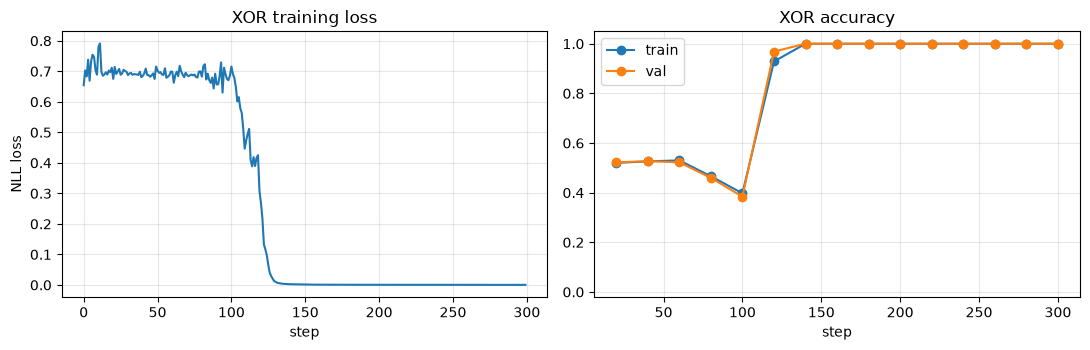

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(losses, color="tab:blue")
axes[0].set_title("XOR training loss")
axes[0].set_xlabel("step")
axes[0].set_ylabel("NLL loss")
axes[0].grid(alpha=0.3)

axes[1].plot(eval_steps, train_accs, marker="o", label="train")
axes[1].plot(eval_steps, val_accs, marker="o", label="val")
axes[1].set_title("XOR accuracy")
axes[1].set_xlabel("step")
axes[1].set_ylim(-0.02, 1.05)
axes[1].grid(alpha=0.3)
axes[1].legend()
plt.tight_layout()
plt.show()


## 4. Проверка обученной модели против torch

Собираем эквивалентную torch-модель, загружаем в неё веса NumPy-модели и сравниваем
логиты на валидационной выборке. Это проверяет не только отдельные операции, но и
всю обученную композицию.

In [7]:
class TorchTinyClassifier(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = torch.nn.Linear(VOCAB, D_MODEL, dtype=torch.float64)
        self.pos = torch.nn.Parameter(torch.zeros((SEQ_LEN, 1, D_MODEL), dtype=torch.float64))
        encoder_layer = torch.nn.TransformerEncoderLayer(
            D_MODEL,
            NHEAD,
            dim_feedforward=FFN,
            dropout=0.0,
            dtype=torch.float64,
        )
        self.encoder = torch.nn.TransformerEncoder(
            encoder_layer,
            N_LAYERS,
            norm=torch.nn.LayerNorm(D_MODEL, dtype=torch.float64),
            enable_nested_tensor=False,
        )
        self.head = torch.nn.Linear(D_MODEL, VOCAB, dtype=torch.float64)

    def forward(self, onehot):
        hidden = self.embed(onehot) + self.pos
        hidden = self.encoder(hidden)
        return self.head(hidden.mean(dim=0))


torch_model = TorchTinyClassifier()
torch_model.load_state_dict(
    {key: torch.tensor(value) for key, value in model.state_dict().items()}
)
torch_model.eval()
model.eval()

with torch.no_grad():
    logits_t = torch_model(torch.tensor(x_val))
with no_grad():
    logits_n = model(Tensor(x_val.copy()))

print(f"trained model logits maxdiff: {maxdiff(logits_n.data, logits_t.numpy()):.3e}")
print(f"torch val accuracy         : {(torch.argmax(logits_t, dim=1).numpy() == labels_val).mean():.3f}")
print(f"numpy val accuracy         : {(np.argmax(logits_n.data, axis=1) == labels_val).mean():.3f}")


trained model logits maxdiff: 2.665e-15
torch val accuracy         : 1.000
numpy val accuracy         : 1.000


## Итог

- NumPy-слой и стек `TransformerEncoder` совпадают с torch по forward/backward.
- Tiny-классификатор обучается на XOR первых/последних токенов и выходит на 100%
  accuracy на train/val.
- Обученная NumPy-модель численно совпадает с torch-двойником после загрузки весов;
  расхождение логитов ~1e-15.

Полный набор тестов: `tests/` (`../.venv/bin/python -m unittest discover -s tests -t . -v`),
описание — в `README.md`.